# LabelStoma: stomata detection with the released YOLO model — minimal CPU reproduction

**Paper:** A. Casado-García, A. del-Canto, A. Sanz-Saez, U. Pérez-López, A. Bilbao-Kareaga, F. B. Fritschi, J. Miranda-Apodaca, V. Muñoz-Rueda, A. Sillero-Martínez, A. Yoldi-Achalandabaso, M. Lacuesta, J. Heras. *LabelStoma: A tool for stomata detection based on the YOLO algorithm.* **Computers and Electronics in Agriculture 178 (Nov 2020), 105751.** DOI: [10.1016/j.compag.2020.105751](https://doi.org/10.1016/j.compag.2020.105751)

**Author code:** [github.com/ancasag/labelStoma](https://github.com/ancasag/labelStoma) @ commit `6355fc7e62ef148a9a961678e1c2725ab1dbd07e`.

**Scope (partial demonstration).** This notebook executes the paper's core result — automatic stomata detection on a leaf microscope image — by running the **released pretrained YOLOv3 weights** through the exact inference path of the LabelStoma GUI's *detect stomata* action (`predict/detectStoma.py`), ported headlessly. On one image we: load the author's Darknet config/weights, run OpenCV-DNN inference with the author's parameters (confidence 0.25, NMS 0.45, 1024×1024 blob), draw predicted boxes next to the author's reference XML annotation, and export the author's Pascal-VOC-style detection XML. GUI chrome, retraining, test-time augmentation, progressive resizing, and the multi-image Excel statistics are **out of scope**. One-image detection is *not* a verification of the paper's dataset-level F1 = 0.91.

**AI-assisted adaptation notice / AI支援に関する明記:** LabelStoma is a Qt GUI; the authors did not provide this headless Colab implementation. The detection logic below is copied verbatim from the authors' `predict/detectStoma.py` (commit `6355fc7`); only GUI plumbing and multi-file iteration were removed. The executed example and listed checks were validated, but untested behavior is not guaranteed. / LabelStomaはQt GUIであり、著者自身はこのヘッドレスColab実装を提供していません。検出処理は著者コードからのほぼそのままの移植で、GUI部分と複数ファイル処理のみ省略しています。

**日本語の要約:** このNotebookは、LabelStomaが公開している学習済みYOLOv3重みを、著者コード（`predict/detectStoma.py`）と同じ手順（OpenCV DNN、confidence 0.25、NMS 0.45、入力1024×1024）でCPU上で実行し、顕微鏡画像1枚の気孔(stomata)検出を再現します。著者のデータセットに含まれる参照アノテーション(XML)と検出結果を比較して描画し、著者形式のXMLも出力します。

## Runtime selection / 実行環境の選択

**Select `CPU` runtime (Runtime → Change runtime type → CPU). No GPU is needed**: the authors' prediction code explicitly pins `cv.dnn.DNN_TARGET_CPU` (`predict/detectStoma.py`, commit `6355fc7`), so the CPU path *is* the faithful path. Single-image YOLOv3 inference at 1024×1024 takes on the order of a minute on a Colab CPU core.

Downloads (all inside this notebook, into the Colab VM): Darknet `.cfg`/`.names` from the pinned author commit (~10 KB), pretrained `yolov3Stomata.weights` from the authors' Dropbox link hardcoded in their code (expected ≈200 MB), and one sample image + reference XML extracted from the authors' example dataset archive (size measured below).

**Run all** (`Runtime → Run all`) from a fresh CPU runtime. Expected end-to-end: roughly 5–10 minutes, dominated by downloads. / **CPUランタイムを選択してください。GPUは不要です。** 推論はCPUで行われます（著者コードがCPUを指定）。Run allでの想定所要時間はダウンロード込みで約5〜10分です。

### Compatibility: pin OpenCV 4.x for the author's Darknet loader

The authors' prediction path relies on OpenCV's **Darknet importer** (`cv2.dnn.readNet(weights, cfg)`), which current Colab images (OpenCV 5.0) have **removed**. We therefore pin the last OpenCV 4 line (4.14.0.94 — the same 4.x generation already shipped with Colab), after removing the conflicting preinstalled OpenCV packages. This is the single deliberate compatibility adaptation of this notebook; everything else follows the author code. A runtime restart is not required as long as this cell runs before `cv2` is first imported (Run all does this).

/ 著者コードはOpenCVのDarknet読み込み（`cv2.dnn.readNet`）に依存しますが、最新のColabイメージ（OpenCV 5.0）では削除されています。そのためOpenCV 4.14.0.94へ固定します（本Notebookで唯一の意図的な互換性対応です）。Run allでは最初にこのセルが実行されるため、再起動は不要です。

In [ ]:
import subprocess

pkgs = ["opencv-python", "opencv-contrib-python", "opencv-python-headless"]
print(subprocess.run(["pip", "uninstall", "-y", *pkgs], capture_output=True, text=True).stdout[-400:])
r = subprocess.run(["pip", "install", "-q", "opencv-python==4.14.0.94"], capture_output=True, text=True)
print("pip install opencv-python==4.14.0.94 rc:", r.returncode)
assert r.returncode == 0, r.stderr[-500:]

-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93



pip install opencv-python==4.14.0.94 rc: 0


### Verify the environment after the pin

We confirm the interpreter, NumPy, and the pinned OpenCV 4.x (the Darknet importer is only asserted to work later, when the weights are actually loaded).

/ インストール後、Python・NumPy・OpenCVのバージョンを確認します。

In [ ]:
import sys, platform
print("Python:", sys.version)
import numpy as np, cv2
print("numpy:", np.__version__)
print("opencv:", cv2.__version__)
assert cv2.__version__.startswith("4."), "OpenCV 4.x required for the Darknet importer"
print("platform:", platform.platform())

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


numpy: 2.1.3
opencv: 4.14.0
platform: Linux-6.6.159+-x86_64-with-glibc2.39


## 1. Model config and class names from the pinned author commit

LabelStoma's detector needs three files: the Darknet configuration `fichs/yolov3Estomas.cfg`, the class list `fichs/vocEstomas.names`, and the pretrained weights (next section). We fetch the two small text files directly from the authors' repository at the pinned commit `6355fc7e62ef148a9a961678e1c2725ab1dbd07e` (raw.githubusercontent.com), and verify the downloaded bytes: the `.cfg` must start with the `[net]` section and the `.names` file lists the single class `stoma`.

/ 著者リポジトリの固定コミットから、Darknet設定ファイル（`yolov3Estomas.cfg`）とクラス名ファイル（`vocEstomas.names`）を取得し、内容（`[net]`で始まること、クラス`stoma`）を検証します。

In [ ]:
import requests, hashlib
from pathlib import Path

COMMIT = "6355fc7e62ef148a9a961678e1c2725ab1dbd07e"
BASE = f"https://raw.githubusercontent.com/ancasag/labelStoma/{COMMIT}"

def fetch_bytes(url, min_bytes=1):
    r = requests.get(url, timeout=300)
    r.raise_for_status()
    data = r.content
    assert len(data) >= min_bytes, f"too small: {len(data)} bytes"
    assert not data.lstrip().startswith(b"<!DOCTYPE") and not data.lstrip().startswith(b"<html"), \
        f"HTML error page, not content: {url}"
    return data

cfg = fetch_bytes(f"{BASE}/fichs/yolov3Estomas.cfg")
names = fetch_bytes(f"{BASE}/fichs/vocEstomas.names")

assert cfg.lstrip().startswith(b"[net]"), "unexpected cfg content"
classes = names.decode().strip().splitlines()
print("classes:", classes)
CFG_PATH = Path("/content/yolov3Estomas.cfg"); CFG_PATH.write_bytes(cfg)
NAMES_PATH = Path("/content/vocEstomas.names"); NAMES_PATH.write_bytes(names)
print("cfg bytes:", len(cfg), "sha256:", hashlib.sha256(cfg).hexdigest()[:16], "->", CFG_PATH)
print("names bytes:", len(names), "->", NAMES_PATH)

classes: ['stoma']
cfg bytes: 8335 sha256: 7e396d312ede1a5f -> /content/yolov3Estomas.cfg
names bytes: 6 -> /content/vocEstomas.names


## 2. Pretrained stomata weights (author-distributed)

The LabelStoma prediction code hardcodes the pretrained weight file and its download URL (`predict/detectStoma.py`, commit `6355fc7`): `https://www.dropbox.com/s/fce0bsyl12enh4e/yolov3Stomata.weights?dl=1`. These are the authors' released YOLOv3 weights (GPLv3, per the repository README). We download them here into the Colab VM, reject any HTML error page, and report the exact byte count and SHA-256. Expected size is of the order of 200 MB for a standard YOLOv3 model; we assert a generous plausible range rather than an unverified exact number.

/ 著者コードに記載されたDropboxのURLから学習済み重み `yolov3Stomata.weights` をColab VM内にダウンロードし、HTMLエラーでないこと・サイズとSHA-256を確認します。

In [ ]:
import time

WEIGHTS_URL = "https://www.dropbox.com/s/fce0bsyl12enh4e/yolov3Stomata.weights?dl=1"
t0 = time.time()
weights = fetch_bytes(WEIGHTS_URL, min_bytes=1_000_000)
download_s = time.time() - t0
assert len(weights) > 10_000_000, f"weights implausibly small: {len(weights)} bytes"
WEIGHTS_PATH = Path("/content/yolov3Stomata.weights")
WEIGHTS_PATH.write_bytes(weights)
print(f"weights: {len(weights)/1e6:.1f} MB in {download_s:.1f} s")
print("sha256:", hashlib.sha256(weights).hexdigest())

weights: 246.3 MB in 5.0 s


sha256: 8ca4dbca81d40bc5c9f1f1ee1196d7b44b8a751d453cee626bdc0035dd7030cc


## 3. Sample image with the authors' reference annotation

We use one deterministic sample from the authors' own example dataset: the example notebook that LabelStoma generates for model customization (`YOLOExampleDDStoma.ipynb`, linked from the repository README) downloads `dataset.zip` from the authors' Dropbox and processes a Darknet/VOC directory tree (`dataset/train/JPEGImages`, `dataset/test/JPEGImages` with sibling `.xml` Pascal-VOC annotations). We download the same archive into the Colab VM, report its size, and validate it as a real ZIP. The whole archive is required to reach the single sample (no per-file URL is published); its full size is measured and reported below.

/ 著者の例示ノートブックと同じ `dataset.zip`（著者Dropbox、Darknet/VOC構成、XMLアノテーション付き）をColab内にダウンロードします。サンプル1枚のためにアーカイブ全体の取得が必要である旨と、実サイズを表示します。

In [ ]:
import zipfile, os

DATASET_URL = "https://www.dropbox.com/s/6cftaw2iuhoom97/dataset.zip?dl=1"
ZIP_PATH = Path("/content/dataset.zip")
t0 = time.time()
zdata = fetch_bytes(DATASET_URL, min_bytes=1_000_000)
ZIP_PATH.write_bytes(zdata)
print(f"dataset.zip: {len(zdata)/1e6:.1f} MB in {time.time()-t0:.1f} s, sha256:", hashlib.sha256(zdata).hexdigest()[:16])

EXTRACT_DIR = Path("/content/stoma_dataset")
with zipfile.ZipFile(ZIP_PATH) as zf:  # raises BadZipFile if the payload is not a real zip
    names = zf.namelist()
    print("members:", len(names))
    sample_members = [n for n in names if n.lower().endswith((".jpg", ".jpeg", ".png"))]
    print("image members:", len(sample_members), "example:", sample_members[0] if sample_members else None)
    zf.extractall(EXTRACT_DIR)
os.remove(ZIP_PATH)

dataset.zip: 19.1 MB in 2.0 s, sha256: 29f8ff079826cb18
members: 932
image members: 468 example: dataset/test/JPEGImages/23_6_1054.jpg


### Choose the deterministic held-out sample

In this archive the reference XMLs live in a parallel `labels` directory (`dataset/test/labels/*.xml`), not beside the images, and some annotated files legitimately contain zero stomata. We therefore pair each image with its same-stem XML, keep only samples whose reference annotation contains **at least one stoma box** (the authors' label strings are `stomata` and `estoma` — Spanish), prefer the **test split** (held out from training), and take the first sample in sorted filename order. The rule is deterministic for this archive and does not cherry-pick a good-looking result; the selected sample is printed. The XML `<size>` header in this dataset still records the original microscope image, but all box coordinates are verified to lie inside the shipped image dimensions.

/ このアーカイブでは参照XMLは `labels` ディレクトリにあり、ラベル名は `stomata`/`estoma` です。参照ボックスを1つ以上含むtestサンプルのうち、ソート順で最初の1枚を決定的に選択します。

In [ ]:
STOMA_LABELS = {"stoma", "stomata", "estoma"}

def find_samples(root):
    samples = []
    for dirpath, _, filenames in os.walk(root):
        if not dirpath.lower().endswith("jpegimages"):
            continue
        labels_dir = os.path.join(os.path.dirname(dirpath), "labels")
        for fn in sorted(filenames):
            if fn.lower().endswith((".jpg", ".jpeg", ".png")):
                stem = os.path.splitext(fn)[0]
                xml = os.path.join(dirpath, stem + ".xml")          # XML beside image (train)
                if not os.path.exists(xml):
                    xml = os.path.join(labels_dir, stem + ".xml")   # XML in labels/ (test)
                if os.path.exists(xml) and read_stoma_count(xml) >= 1:
                    samples.append((os.path.join(dirpath, fn), xml))
    return samples

def read_stoma_count(xml_path):
    root = ET.parse(xml_path).getroot()
    return sum(1 for o in root.iter("object")
               if (o.findtext("name") or "").strip().lower() in STOMA_LABELS)

import xml.etree.ElementTree as ET  # needed by the selector above

all_samples = find_samples(EXTRACT_DIR)
test_samples = [s for s in all_samples if os.sep + "test" + os.sep in s[0] or "/test/" in s[0]]
SPLIT = "test" if test_samples else "train"
pool = test_samples or all_samples
assert pool, "no image with a reference stoma box found in the archive"
IMAGE_PATH, XML_PATH = sorted(pool)[0]
print("split used:", SPLIT, "| paired samples:", len(all_samples), "| test:", len(test_samples))
print("sample image:", IMAGE_PATH)
print("reference XML:", XML_PATH)

split used: test | paired samples: 437 | test: 110
sample image: /content/stoma_dataset/dataset/test/JPEGImages/0_4_1044.jpg
reference XML: /content/stoma_dataset/dataset/test/labels/0_4_1044.xml


### Input preview with the authors' reference annotation (not model output)

Before running the method, we display the actual sample with the authors' **reference** stomata boxes drawn in green. This preview comes straight from the archive downloaded above — it is source data, not a prediction. The image is shown in original orientation with axes in pixels.

/ 実行前に、アーカイブから取得したサンプル画像と著者の参照アノテーション（緑の枠）を表示します。これはデータの確認であり、モデルの出力ではありません。

image: 400x400px, reference stomata boxes: 5


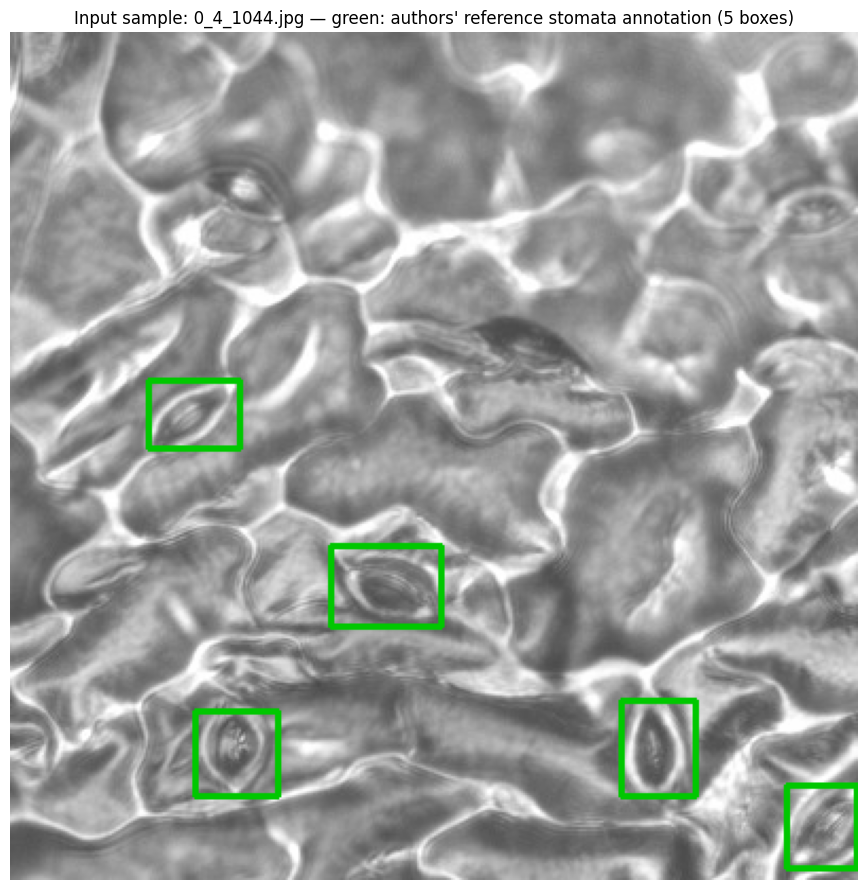

In [ ]:
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

def read_voc_boxes(xml_path):
    root = ET.parse(xml_path).getroot()
    boxes = []
    for obj in root.iter("object"):
        name = (obj.findtext("name") or "").strip().lower()
        if name not in STOMA_LABELS:
            continue
        bb = obj.find("bndbox")
        boxes.append((int(float(bb.findtext("xmin"))), int(float(bb.findtext("ymin"))),
                      int(float(bb.findtext("xmax"))), int(float(bb.findtext("ymax")))))
    return boxes

frame_bgr = cv2.imread(IMAGE_PATH)
assert frame_bgr is not None, "cv2 could not read the sample image"
H, W = frame_bgr.shape[:2]
ref_boxes = read_voc_boxes(XML_PATH)
print(f"image: {W}x{H}px, reference stomata boxes: {len(ref_boxes)}")

frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
preview = frame_rgb.copy()
for (x1, y1, x2, y2) in ref_boxes:
    cv2.rectangle(preview, (x1, y1), (x2, y2), (0, 200, 0), 2)
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(preview)
ax.set_title(f"Input sample: {os.path.basename(IMAGE_PATH)} — green: authors' reference stomata annotation ({len(ref_boxes)} boxes)")
ax.axis("off")
plt.tight_layout(); plt.savefig("/content/preview_reference.png", dpi=100, bbox_inches="tight"); plt.show()

## 4. Core method: the authors' detection step, verbatim

This cell is a port of the authors' inference logic from `predict/detectStoma.py` (commit `6355fc7`): `getOutputsNames`, `postprocess` (confidence filter `confThreshold = 0.25`, `cv.dnn.NMSBoxes` with `nmsThreshold = 0.45`), and the network invocation from `generateXMLFromImage` — `cv.dnn.readNet(weights, cfg)` with `DNN_BACKEND_OPENCV` + `DNN_TARGET_CPU`, and `blobFromImage(frame, 1/255, (1024, 1024), [0, 0, 0], 1, crop=False)` (the authors hardcode the 1024×1024 input regardless of the cfg text). The only changes: (1) the weights/cfg paths point to the files downloaded above; (2) the function takes the image path as an argument instead of a global; (3) two **shape-robust indexing** tweaks — modern OpenCV returns `getUnconnectedOutLayers()` as a flat array and `NMSBoxes` indices as a flat list, so we flatten before indexing (the authors' `i[0]` assumed the old `(N,1)` shape). Numerical behavior is unchanged. Output: pixel-coordinate boxes and confidences, exactly as the GUI would produce before writing its XML.

/ 著者コード `predict/detectStoma.py` の推論処理（閾値0.25、NMS 0.45、1024×1024、OpenCV DNN・CPU）を移植して実行します。新しいOpenCVでのインデックス形状の違い（`(N,1)`→`(N,)`）のみを吸収し、数値動作は変えていません。

In [ ]:
confThreshold = 0.25  # Confidence threshold (predict/detectStoma.py L14)
nmsThreshold = 0.45   # Non-maximum suppression threshold (L15)

def getOutputsNames(net):
    layersNames = net.getLayerNames()
    # author L25 indexed i[0]; modern OpenCV returns flat indices — ravel handles both
    return [layersNames[int(np.asarray(i).ravel()[0]) - 1] for i in net.getUnconnectedOutLayers()]

def postprocess(frame, outs, conf):
    frameHeight, frameWidth = frame.shape[0], frame.shape[1]
    classIds, confidences, boxes = [], [], []
    for out in outs:
        for detection in out:
            scores = detection[5:]
            classId = np.argmax(scores)
            confidence = scores[classId]
            if confidence > conf:
                center_x = int(detection[0] * frameWidth)
                center_y = int(detection[1] * frameHeight)
                width = int(detection[2] * frameWidth)
                height = int(detection[3] * frameHeight)
                left = int(center_x - width / 2)
                top = int(center_y - height / 2)
                classIds.append(classId)
                confidences.append(float(confidence))
                boxes.append([left, top, width, height])
    indices = np.asarray(cv2.dnn.NMSBoxes(boxes, confidences, conf, nmsThreshold)).reshape(-1)
    newBoxes = [boxes[int(i)] for i in indices]
    newConfi = [confidences[int(i)] for i in indices]
    return newBoxes, newConfi

def detect_stomata(image_path, conf=confThreshold):
    net = cv2.dnn.readNet(str(WEIGHTS_PATH), str(CFG_PATH))  # (weights, cfg) — author L165
    net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)     # author L166
    net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)          # author L167
    frame = cv2.imread(str(image_path))
    blob = cv2.dnn.blobFromImage(frame, 1 / 255, (1024, 1024), [0, 0, 0], 1, crop=False)  # author L183
    net.setInput(blob)
    outs = net.forward(getOutputsNames(net))
    return frame, postprocess(frame, outs, conf)

t0 = time.time()
frame_bgr, (pred_boxes, pred_confs) = detect_stomata(IMAGE_PATH)
infer_s = time.time() - t0
print(f"detections: {len(pred_boxes)} in {infer_s:.1f} s (CPU forward pass)")

detections: 4 in 15.1 s (CPU forward pass)


## 5. Results: predictions vs. the authors' reference annotation

We draw the model's detections (red) next to the reference annotation (green) on the same image, plus a small table of predicted boxes with confidences. As a lightweight plausibility check (not a paper metric), we count detections matched to a reference box at IoU ≥ 0.5. Differences are expected: the paper reports dataset-level F1 = 0.91, and a single image—especially from the test split—will not reproduce that aggregate.

/ 検出結果（赤）と参照アノテーション（緑）を並べて描画し、信頼度付きの検出表と、IoU≥0.5の一致数（妥当性確認用、論文の指標ではない）を示します。

predicted: 4 | reference: 5 | matched (IoU>=0.5): 4


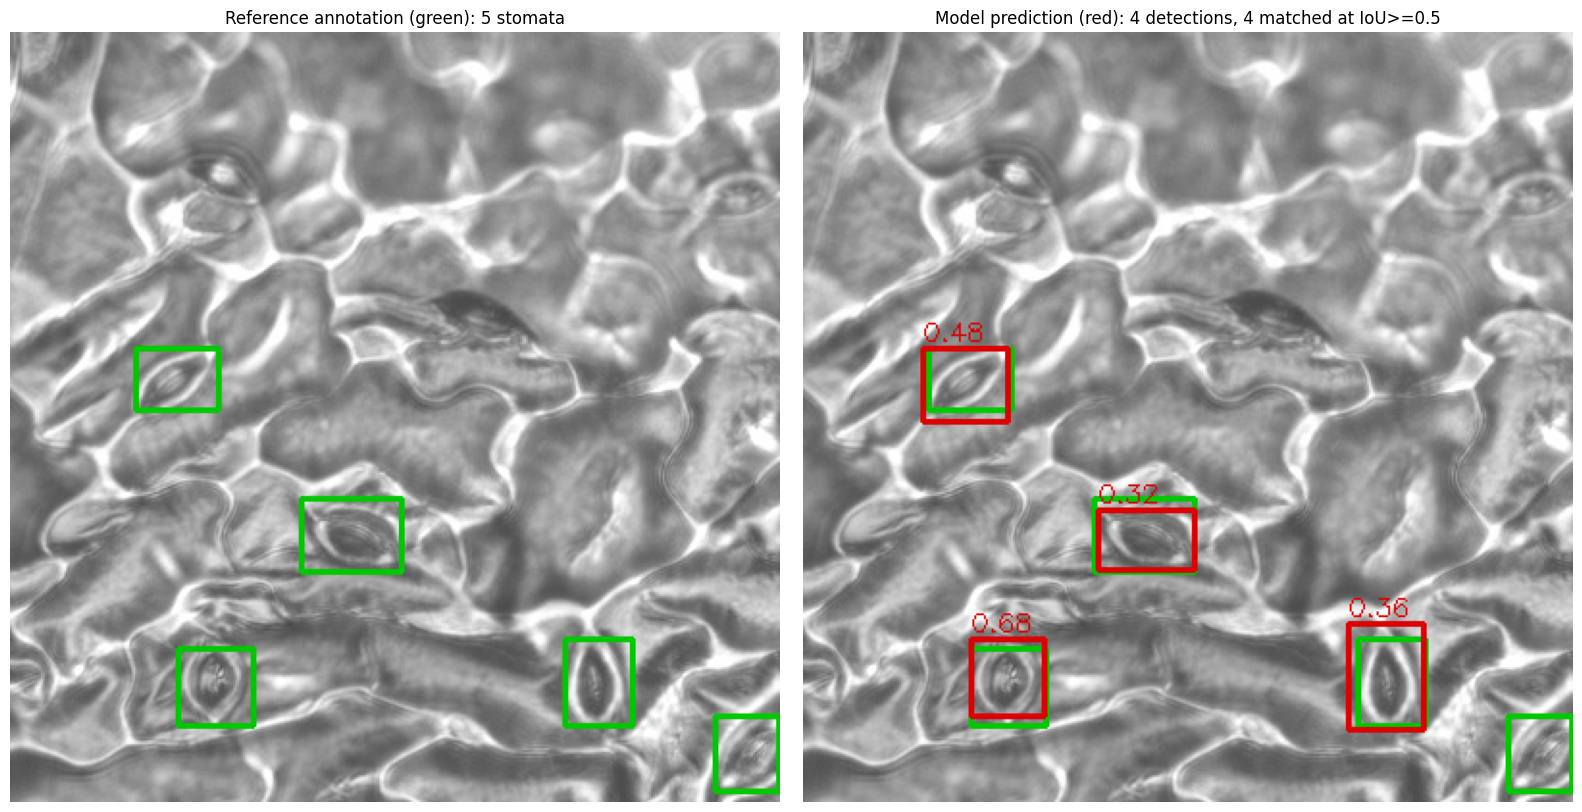

,left,top,width,height,confidence
0,87,315,38,40,0.682641
1,62,164,44,38,0.480212
2,283,307,39,55,0.355997
3,153,248,50,31,0.317131


In [ ]:
def iou(a, b):
    ax1, ay1, ax2, ay2 = a; bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    union = (ax2-ax1)*(ay2-ay1) + (bx2-bx1)*(by2-by1) - inter
    return inter / union if union else 0.0

pred_xyxy = [(x, y, x + w, y + h) for (x, y, w, h) in pred_boxes]
matched = sum(1 for p in pred_xyxy if any(iou(p, r) >= 0.5 for r in ref_boxes))
print(f"predicted: {len(pred_boxes)} | reference: {len(ref_boxes)} | matched (IoU>=0.5): {matched}")

overlay = frame_rgb.copy()
for (x1, y1, x2, y2) in ref_boxes:
    cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 200, 0), 2)   # green: reference
for (x1, y1, x2, y2), c in zip(pred_xyxy, pred_confs):
    cv2.rectangle(overlay, (x1, y1), (x2, y2), (220, 0, 0), 2)   # red: prediction
    cv2.putText(overlay, f"{c:.2f}", (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (220, 0, 0), 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(preview); axes[0].set_title(f"Reference annotation (green): {len(ref_boxes)} stomata"); axes[0].axis("off")
axes[1].imshow(overlay); axes[1].set_title(f"Model prediction (red): {len(pred_boxes)} detections, {matched} matched at IoU>=0.5"); axes[1].axis("off")
plt.tight_layout(); plt.savefig("/content/results_comparison.png", dpi=100, bbox_inches="tight"); plt.show()

import pandas as pd
display(pd.DataFrame(pred_boxes, columns=["left", "top", "width", "height"]).assign(confidence=pred_confs))

### Export in the authors' XML format

LabelStoma saves each detection as a Pascal-VOC-style annotation with an added `<confidence>` element (`generateXML`, `predict/detectStoma.py` L117–160). We reproduce that exact format for this image and show the first lines. The full file is saved on the Colab VM next to the image, like the GUI does.

/ 著者の `generateXML` と同じ形式（Pascal VOC + `<confidence>` 要素）で検出結果をXMLに保存し、先頭を表示します。

In [ ]:
from xml.dom import minidom

def generate_xml(filename, w, h, d, boxes, confidences):
    top = ET.Element('annotation')
    ET.SubElement(top, 'folder').text = 'images'
    ET.SubElement(top, 'filename').text = filename[0:filename.rfind(".")]
    ET.SubElement(top, 'path').text = ""
    src = ET.SubElement(top, 'source'); ET.SubElement(src, 'database').text = 'Unknown'
    size = ET.SubElement(top, 'size')
    ET.SubElement(size, 'width').text = str(w); ET.SubElement(size, 'height').text = str(h); ET.SubElement(size, 'depth').text = str(d)
    ET.SubElement(top, 'segmented').text = '0'
    for box, con in zip(boxes, confidences):
        obj = ET.SubElement(top, 'object')
        ET.SubElement(obj, 'name').text = 'stoma'
        ET.SubElement(obj, 'pose').text = 'Unspecified'
        ET.SubElement(obj, 'truncated').text = '0'
        ET.SubElement(obj, 'difficult').text = '0'
        ET.SubElement(obj, 'confidence').text = str(con)
        bb = ET.SubElement(obj, 'bndbox')
        x, y, wb, hb = box
        ET.SubElement(bb, 'xmin').text = str(x); ET.SubElement(bb, 'ymin').text = str(y)
        ET.SubElement(bb, 'xmax').text = str(x + wb); ET.SubElement(bb, 'ymax').text = str(y + hb)
    return minidom.parseString(ET.tostring(top, 'utf-8')).toprettyxml(indent="  ")

xml_text = generate_xml(os.path.basename(IMAGE_PATH), W, H, frame_bgr.shape[2], pred_boxes, pred_confs)
OUT_XML = os.path.splitext(IMAGE_PATH)[0] + "_detected.xml"
with open(OUT_XML, "w") as f:
    f.write(xml_text)
print("wrote", OUT_XML)
print("\n".join(xml_text.splitlines()[:12]))

wrote /content/stoma_dataset/dataset/test/JPEGImages/0_4_1044_detected.xml
<?xml version="1.0" ?>
<annotation>
  <folder>images</folder>
  <filename>0_4_1044</filename>
  <path/>
  <source>
    <database>Unknown</database>
  </source>
  <size>
    <width>400</width>
    <height>400</height>
    <depth>3</depth>


## 6. Interpretation and validation record / 解釈と検証記録

- **What ran:** the authors' released pretrained YOLOv3 stomata detector (`yolov3Stomata.weights`) through their own OpenCV-DNN inference path (`predict/detectStoma.py` @ `6355fc7`: confidence 0.25, NMS 0.45, 1024×1024 input, CPU backend), executed on one held-out sample image from the authors' example dataset, with their reference XML annotation for comparison.
- **How to read the result:** predicted (red) vs. reference (green) boxes above, the matched count at IoU ≥ 0.5, and the exported author-format XML. This is a per-image demonstration; it does not reproduce the paper's dataset-level F1 = 0.91 and does not exercise the GUI, retraining, TTA, progressive resizing, or the Excel statistics.
- **Provenance:** weights and dataset from the authors' own Dropbox links (the weights URL is hardcoded in the authors' code; the dataset URL comes from the authors' example notebook); `.cfg`/`.names` from the pinned commit. Sizes and SHA-256 are printed in the outputs above; the cfg/names/weights/sample were validated in Colab at execution time.
- **Expected variation:** the exact sample chosen is deterministic for the archive; detection counts may vary slightly with OpenCV version. Free-tier Colab hardware and network speed may change wall-clock times.

/ **実行内容:** 著者公開の学習済み重みと推論コード（confidence 0.25, NMS 0.45, 1024×1024, CPU）を用いて、著者データセットのtestサンプル1枚の気孔検出を再現しました。**論文のデータセット全体のF1値の検証ではありません。**

### References
- Casado-García et al., *LabelStoma: A tool for stomata detection based on the YOLO algorithm*, Comput. Electron. Agric. 178 (2020) 105751. DOI 10.1016/j.compag.2020.105751
- LabelStoma repository: https://github.com/ancasag/labelStoma (commit `6355fc7e62ef148a9a961678e1c2725ab1dbd07e`), GPLv3.
- Authors' example notebook `YOLOExampleDDStoma.ipynb` (linked from the repository README) — source of the `dataset.zip` URL and Darknet workflow.